---

# **Rigid Body Equilibrium Simulator**

---

A Python-based computational physics project for analyzing
the equilibrium of a hinged support rod.

---

<br>

<br>

---

## [ 1 ] **Project Information**

---

- **Subject:** Computational Physics
- **Grade:** XI
- **Group:** 6
- **Topic:** Rigid Body Equilibrium (Hinged Support Rod)

---

<br>

<br>

---

## [ 2 ] **Group Members**

---

- Jeremy Sebastian Edward Limasnsantoso
- Saridi

---

<br>

<br>

---

## [ 3 ] **Project Objective**

---

This project aims to translate the analytical physics equations
of rigid body equilibrium into a computational model using Python.

The program calculates the cable tension and hinge reaction forces
acting on a horizontally positioned support rod, and visualizes
the relationship between cable tension and hanging mass.

The computational results are compared with manual calculations
to verify their numerical accuracy.

---

<br>

<br>

---

## [ 4 ] **Physical System**

---

The system consists of a homogeneous horizontal rod
attached to a vertical wall using a hinge at point O.

The rod is supported by a steel cable inclined at an
elevation angle α. A static load is suspended from
the outer end of the rod.

The system is assumed to remain in static equilibrium.

---

<br>

<br>

---

## [ 5 ] **Mathematical Model**

---

The system is analyzed using the conditions of
rotational and translational equilibrium.

### **Rotational Equilibrium**

The net torque about the hinge point O is zero.

### **Translational Equilibrium**

The net horizontal and vertical forces acting on
the system are zero.

The resulting equations are used to calculate:

- Cable tension (T)
- Horizontal hinge reaction (Rx)
- Vertical hinge reaction (Ry)

---

<br>

<br>

---

## [ 6 ] **Computational Method**

---

The mathematical model is implemented using Python.

The computational implementation uses the following
libraries:

- NumPy: numerical calculations and trigonometric functions.
- Matplotlib: graphical visualization.

The program uses physical parameters as input to
calculate the cable tension and hinge reaction forces.

---

<br>

<br>

---

### **Library Imports**

---

The following Python libraries are used in this project:

- NumPy for numerical calculations and trigonometric functions.
- Matplotlib for graphical visualization.

---

<br><br>

In [50]:
import numpy as np
import matplotlib.pyplot as plt

<br><br>

---

### **Physical Parameters**

---

The following physical parameters define the initial condition
of the system. These values can be modified to test the
computational model under different conditions.

---

<br><br>

In [51]:
# Physical Parameters
rod_mass = 4.0          # Mass of the rod (kg)
rod_length = 2.0          # Length of the rod (m)
load_mass = 6.0    # Hanging load mass (kg)
alpha_deg = 30.0 # Cable elevation angle (degrees)
gravity = 9.8          # Gravitational acceleration (m/s^2)

<br><br>

---

### **Main Equilibrium Function**

---

This section defines the main function used to calculate the equilibrium forces acting on the beam.

The function uses the physical parameters defined in the previous section to calculate three quantities:

- **Cable Tension (T):** The tension force exerted by the supporting cable.
- **Horizontal Hinge Reaction (Rx):** The horizontal reaction force at the hinge.
- **Vertical Hinge Reaction (Ry):** The vertical reaction force at the hinge.

The cable angle is converted from degrees to radians before applying trigonometric functions. The calculations follow the mathematical model described in the previous section.

The function returns all three force values for further analysis and visualization.

---
<br><br>

In [52]:
# Main Equilibrium Function
def calculate_beam_equilibrium(beam_mass, beam_length, load_mass, cable_angle_deg, g=9.8):

    # Validate numeric input types and finite values
    parameters = {
        "beam_mass": beam_mass,
        "beam_length": beam_length,
        "load_mass": load_mass,
        "cable_angle_deg": cable_angle_deg,
        "g": g
    }

    for name, value in parameters.items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(
            value, (int, float, np.integer, np.floating)
        ):
            raise TypeError(f"{name} must be a numeric value.")

        try:
            parameters[name] = float(value)
        except (OverflowError, ValueError):
            raise ValueError(f"{name} must be a finite number.")

        if not np.isfinite(parameters[name]):
            raise ValueError(f"{name} must be a finite number.")

    # Validate physical parameter ranges
    beam_mass = parameters["beam_mass"]
    beam_length = parameters["beam_length"]
    load_mass = parameters["load_mass"]
    cable_angle_deg = parameters["cable_angle_deg"]
    g = parameters["g"]

    if beam_mass <= 0:
        raise ValueError("Beam mass must be greater than zero.")

    if beam_length <= 0:
        raise ValueError("Beam length must be greater than zero.")

    if load_mass < 0:
        raise ValueError("Load mass cannot be negative.")

    if not 0 < cable_angle_deg <= 90:
        raise ValueError("Cable angle must be between 0 and 90 degrees.")

    if g <= 0:
        raise ValueError("Gravitational acceleration must be greater than zero.")

    # Convert the angle from degrees to radians
    cable_angle_rad = np.radians(cable_angle_deg)

    # Calculate cable tension
    tension = ((0.5 * beam_mass + load_mass) * g) / np.sin(cable_angle_rad)

    # Calculate horizontal hinge reaction
    reaction_x = tension * np.cos(cable_angle_rad)

    # Calculate vertical hinge reaction
    reaction_y = ((beam_mass + load_mass) * g) - (tension * np.sin(cable_angle_rad))

    # Validate calculation results
    if not np.all(np.isfinite([tension, reaction_x, reaction_y])):
        raise ValueError("Calculation produced an invalid result. Check the input values.")

    return tension, reaction_x, reaction_y

<br><br>

---

## [ 7 ] **Results and Visualization**

---

This section presents the computational results of the rigid body equilibrium model, including the calculated forces acting on the beam and the graphical relationship between hanging load mass and cable tension.

---

<br>

<br>

---

### **Initial Function Test**

---

This section performs an initial test of the equilibrium function using the physical parameters defined earlier.

The function is called with the initial parameter values, and its calculated results are displayed in Newtons (N).

This test verifies that the function executes correctly and produces the expected equilibrium force values before proceeding to further experiments.

---
<br>

<br>

---

### **Numerical Results**

---

Calculate and display the cable tension and hinge reaction forces using the initial physical parameters.

---

<br><br>

In [53]:
# Initial Function Test
tension, reaction_x, reaction_y = calculate_beam_equilibrium(
    rod_mass,
    rod_length,
    load_mass,
    alpha_deg,
    gravity
)

print(f"Cable Tension (T): {tension:.2f} N")
print(f"Horizontal Hinge Reaction (Rx): {reaction_x:.2f} N")
print(f"Vertical Hinge Reaction (Ry): {reaction_y:.2f} N")

Cable Tension (T): 156.80 N
Horizontal Hinge Reaction (Rx): 135.79 N
Vertical Hinge Reaction (Ry): 19.60 N


<br><br>

---

### **Generate Load Mass Samples**

---

Generate 50 evenly spaced load mass values ranging from 0 to 20 kg for the tension calculation and graph visualization.

---

<br><br>

In [54]:
# Generate Load Mass Samples
load_mass_values = np.linspace(0, 20, 50)

<br><br>

---

### **Calculate Tension Values**

---

Calculate the cable tension for each load mass sample and store the results in a list for graph visualization.

---

<br><br>

In [55]:
# Calculate Tension Values
tension_values = []

for mass in load_mass_values:
    tension, _, _ = calculate_beam_equilibrium(
        rod_mass,
        rod_length,
        mass,
        alpha_deg,
        gravity
    )

    tension_values.append(tension)

<br><br>

---

### **Plot Tension vs. Load Mass**

---

Visualize the relationship between hanging load mass and cable tension using a line graph.

---
<br><br>

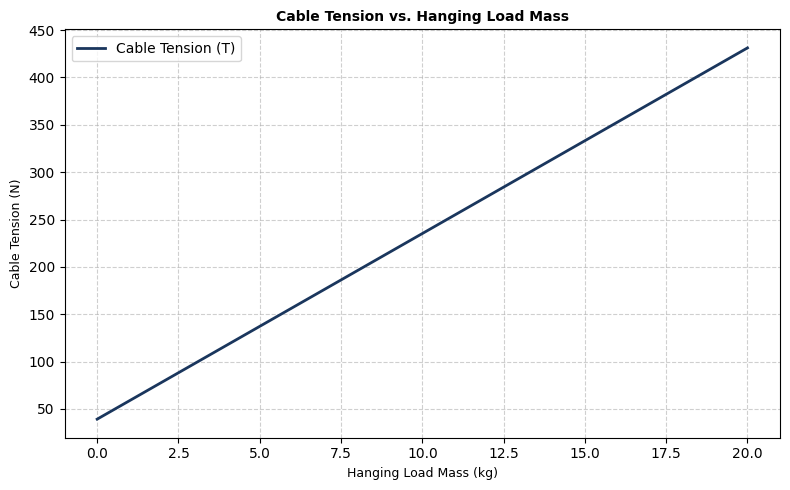

In [56]:
# Plot Tension vs. Load Mass
plt.figure(figsize=(8, 5))

plt.plot(
    load_mass_values,
    tension_values,
    color="#1A365D",
    linewidth=2,
    label="Cable Tension (T)"
)

plt.title("Cable Tension vs. Hanging Load Mass", fontsize=10, fontweight="bold")
plt.xlabel("Hanging Load Mass (kg)", fontsize=9)
plt.ylabel("Cable Tension (N)", fontsize=9)

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

<br><br>

---

### **Graph Interpretation**

---

The graph shows a linear relationship between the hanging load mass and cable tension. As the hanging load mass increases, the cable tension also increases proportionally.

This relationship occurs because the cable tension depends directly on the hanging load mass, while the rod mass, cable angle, and gravitational acceleration remain constant.

For the initial parameters, the cable tension increases from 39.20 N at 0 kg to 431.20 N at 20 kg.

---

<br>

<br>

---

## [ 8 ] **Validation and Discussion**

---

This section evaluates the computational model by comparing its numerical results with the analytical calculations and examining the system's response to variations in physical parameters.

---

<br>


<br>

---

### **Computational Validation**

---

The computational results are compared with the analytical calculations presented in the project report to verify the accuracy of the Python implementation.

---

<br><br>

<div align=center>

| Quantity | Analytical (Manual) | Computational (Python) | Discrepancy |
| :--- | :---:| :---: | :---:|
| T | 156.80 N | 156.80 N | 0.0% |
| Rx | 135.79 N | 135.79 N | 0.0% |
| Ry | 19.60 N | 19.60 N | 0.0% |

</div>

<br><br>

---

### **Parameter Testing**

---

Manual parameter variation experiments were conducted to examine how changes in physical parameters affect the calculated equilibrium forces. A total of 19 experiments were performed across five parameters while keeping the other parameters constant at their initial values.

| Parameter | Tested Values | Observed Behavior |
|---|---|---|
| Rod Mass (kg) | 2, 4, 8 | T, Rx, and Ry increase as rod mass increases. |
| Load Mass (kg) | 0, 3, 6, 12, 20 | T and Rx increase, while Ry remains constant. |
| Cable Angle (°) | 15, 30, 45, 60, 90 | T and Rx decrease as the cable angle increases, while Ry remains constant. |
| Rod Length (m) | 1, 2, 4 | No changes occur in the calculated force values. |
| Gravitational Acceleration (m/s²) | 1.62, 9.8, 24.79 | T, Rx, and Ry increase proportionally with gravitational acceleration. |

These experiments demonstrate that the computational model responds consistently to changes in physical parameters and follows the expected relationships described by the mathematical equations.

---

<br>

<br>

---

### **Scientific Discussion**

---

The parameter variation experiments demonstrate that the computational results follow the mathematical relationships derived from the equilibrium conditions. Increasing the rod mass causes the cable tension and hinge reactions to increase because the rod's weight contributes to the total forces acting on the system. Similarly, increasing the hanging load mass increases the cable tension and horizontal hinge reaction.

However, the vertical hinge reaction remains constant when the hanging load mass and cable angle change. This occurs because its simplified expression is:

$$
R_y = \frac{1}{2}Mg
$$

This expression shows that the vertical hinge reaction depends only on the rod mass and gravitational acceleration.

The experiments also show that increasing the cable angle reduces the cable tension and its horizontal component, while the vertical hinge reaction remains unchanged. Changes in rod length do not affect the calculated forces because the length cancels out when the torque equilibrium equation is derived. Meanwhile, gravitational acceleration affects all calculated forces proportionally. These observations are consistent with the mathematical model and support the expected behavior of the beam system under static equilibrium.

---

<br>

<br>

---

## [ 9 ] **Conclusion**

---

The rigid-body equilibrium simulation was successfully implemented using Python to calculate the cable tension and hinge reaction forces in a hinged beam system. The computational results matched the analytical calculations for the initial parameters, with a discrepancy of 0.0% at the displayed precision.

The parameter variation experiments also demonstrated that the computational model responds consistently to changes in physical parameters and follows the expected relationships derived from the equilibrium equations. Overall, this project demonstrates how computational methods can be used to analyze and examine the static equilibrium of a rigid body system.

---